# DroneID Lab: đi theo một burst thật từ IQ đến CRC16/payload

Kernel **DroneID - baseline** → **Restart Kernel → Run All**, hoặc chạy từng cell bằng Shift+Enter.
Ba cell code đầu: **cấu hình → đọc IQ/kiểm môi trường → detector/chọn burst**. Chỉ đổi cấu hình ở cell đầu.
Biên burst do detector quyết định; chỉ số burst bắt đầu từ **0** như C++/Python (MATLAB từ 1).

**Nguồn:** DSP kế thừa **DroneSecurity `9ff819843bee48fb140a0704ec78aff757896dea`**, có các patch tương thích đã có trong dự án.
`droneid_lab/pipeline.py` là lớp tích hợp dùng chung với app/CLI; notebook/phần hiển thị là phần bổ sung phục vụ học.
**proto17 `7c6dddad563724df93132e91b89e74650182ea1e`: `remove_turbo.cc` đã chạy dưới dạng WebAssembly C/C++**, dùng TurboFEC; chưa chạy bộ thu MATLAB.
Xem [NOTICE](../NOTICE.md), [pipeline](../droneid_lab/pipeline.py), [proto17 process_file.m](../../dji_droneid/matlab/updated_scripts/process_file.m).

Luồng thật: đọc → STFT/Welch tìm burst → dịch tâm/đổi Fs → **CP trước, ZC sau** → FFT → QPSK → Gold XOR → lấy systematic → parse + CRC16.
**Chọn `DECODER_MODE`: baseline giữ systematic-only; turbo dùng cả parity, 4 vòng lặp, CRC24 và CRC16.** Cả hai giữ nguyên DSP trước FEC, chưa đưa equalized vào QPSK.
Turbo cần Node trong PATH (hoặc `DRONEID_NODE`) và `droneid_lab/native/droneid_turbo.wasm`; thiếu backend thì báo lỗi, không fallback. Xem [bằng chứng Turbo](../reports/TURBO_VALIDATION.md).
Đồ thị chẩn đoán không đưa ngược vào decoder. Không sửa mẫu/thuật toán để đạt số đếm cũ.
Output che định danh/toạ độ, không in nguyên byte/bitstream. IQ và biến trong kernel vẫn có thể chứa chúng.

Hai mẫu công khai là các candidate đã cắt/nối; thời gian file không chứng minh chu kỳ phát thực địa.
Kết quả cuối được tính lại trong kernel này; báo cáo cũ chỉ để so sánh, không làm điều kiện pass/fail.

## Cell code 1 — cấu hình duy nhất
Đường dẫn tương đối tính từ thư mục dự án `droneid_lab`. Đổi sang `mavic_air_2` hoặc file IQ của bạn tại đây.
Fs là **mẫu phức/giây**, khác tần số sóng mang Fc; không tự suy chúng từ tên file.
`CHUNK_INDEX` chọn đoạn đọc; `BURST_INDEX` chọn kết quả detector trong đoạn, không phải biên mẫu.
File lớn: đặt `RUN_FULL_FILE=False` để chỉ học chunk chọn. Không tự tải file khi thiếu.

In [1]:
INPUT_FILE = "../droneid_offline_audit_20261116/DroneSecurity/samples/mini2_sm"
FS_HZ = 50_000_000
FC_HZ = None                         # chưa xác minh; không tự gán 2.4 GHz
FORMAT, BYTE_ORDER, IQ_ORDER = "float32", "little", "IQ"
CHUNK_SECONDS, CHUNK_INDEX = 0.5, 0
BURST_INDEX = 0                      # đổi sau khi xem bảng detector
RUN_FULL_FILE = True
RUN_SAMPLE_COMPARISON = True         # chỉ đối chiếu cả hai khi chọn mẫu công khai
DECODER_MODE = "turbo"           # "turbo": bật parity/CRC24; Restart → Run All
print("DECODER_MODE =", repr(DECODER_MODE))
print("Đã đặt cấu hình; chưa đọc hoặc thay đổi file IQ.")

DECODER_MODE = 'turbo'
Đã đặt cấu hình; chưa đọc hoặc thay đổi file IQ.


## 1. Đọc IQ và xác nhận môi trường
**Vấn đề:** Chuyển byte thành số phức đúng định dạng trước khi áp dụng DSP.

**Từ mới:** I/Q là phần thực/ảo; dtype là kiểu số; shape là kích thước mảng. a.u. là biên độ tương đối, chưa hiệu chuẩn điện áp.

**Vào → ra:** File + metadata → chunk_iq, vector complex64; giữ Fs và vị trí chunk trong file.

**Ý tưởng:** `x[n]=I[n]+jQ[n]`, n là chỉ số mẫu, j²=−1; `T=N/Fs`, N là số mẫu phức. Float32 dùng 8 byte/cặp; int16 được chia 32768.

**Python đang chạy:** `pipeline.IQFile.__init__/read`; app/CLI dùng cùng reader. notebook_support.py chỉ trình bày/vẽ hình.

**Đối chiếu proto17:** `read_complex.m`, `get_bytes_per_sample.m`, `get_sample_count_of_file.m`. **Khác nhau:** Python khai báo endian, IQ/QI, đọc memmap theo chunk; proto17 mặc định single, IQ và endian native.

**Quan sát:** Xem interpreter, đường dẫn package, N/Fs, shape/dtype, vài mẫu. Thiếu file thì không tạo dữ liệu thay thế.

**Tự kiểm tra Q1:** Vì sao B byte float32 IQ chứa B/8 mẫu phức? Đáp án ở cuối notebook.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import sys, json, hashlib, importlib.metadata as metadata
import numpy as np
from IPython.display import display, Markdown
roots = [Path.cwd(), *Path.cwd().parents]
LAB = next((p for base in roots for p in (base, base / "droneid_lab")
            if (p / "droneid_lab" / "pipeline.py").is_file()), None)
if LAB is None:
    raise FileNotFoundError("Mở notebook bên trong dự án DroneID_Lab hiện có.")
sys.path.insert(0, str(LAB))
from droneid_lab import pipeline as dsp
pipeline_path = Path(dsp.__file__).resolve()
if not pipeline_path.samefile(LAB / "droneid_lab" / "pipeline.py"):
    raise RuntimeError(f"Kernel đang dùng pipeline từ {pipeline_path}. Mở notebook của dự án này, chọn Restart Kernel rồi Run All.")
missing_api = [name for name in ("confirmed", "decode_fec") if not callable(getattr(dsp, name, None))]
if missing_api:
    raise RuntimeError("Kernel đang giữ pipeline chưa có API: " + ", ".join(missing_api)
                       + ". Chọn Restart Kernel rồi Run All từ cell cấu hình; chỉ Run All không nạp lại module đã import.")
from droneid_lab import notebook_support as view
get_ipython().run_line_magic("matplotlib", "inline")
if DECODER_MODE not in ("baseline", "turbo"):
    raise ValueError(f"DECODER_MODE={DECODER_MODE!r} không hợp lệ. Chỉ nhận 'baseline' hoặc 'turbo' (đủ chữ o cuối). Sửa cell cấu hình rồi chạy lại từ đầu.")
cfg = dsp.Config(fs=FS_HZ, fc=FC_HZ, format=FORMAT, byte_order=BYTE_ORDER,
                 iq_order=IQ_ORDER, chunk_seconds=CHUNK_SECONDS, mode=DECODER_MODE)
input_path = (LAB / Path(INPUT_FILE)).resolve()
RUN_STARTED = datetime.now(timezone.utc).isoformat()
print("Python:", sys.executable, "\nPipeline:", dsp.__file__, "\nIQ:", input_path)
print("API pipeline đã kiểm: confirmed, decode_fec.")
print("Phiên bản:", {p: metadata.version(p) for p in ("numpy", "scipy", "matplotlib", "ipykernel")})
reader = view.stage("đọc IQ", dsp.IQFile, input_path, cfg)
chunk_iq, chunk_start, chunk_end = None, 0, 0
if reader is not None:
    chunk_start = int(CHUNK_INDEX) * int(cfg.chunk_seconds * cfg.fs)
    chunk_end = min(chunk_start + int(cfg.chunk_seconds * cfg.fs), reader.count)
    if 0 <= chunk_start < reader.count:
        chunk_iq = view.stage("đọc chunk", reader.read, chunk_start, chunk_end)
        if chunk_iq is not None:
            view.describe("chunk_iq", chunk_iq, fs=cfg.fs, unit="a.u.", preview=4)
            print(f"Nhận xét: file {reader.count} mẫu = {reader.count/cfg.fs*1e3:.5f} ms; chunk [{chunk_start},{chunk_end}).")
    else:
        print("CHUNK_INDEX ngoài file: đổi cấu hình rồi chạy lại từ đầu.")

Python: e:\Tin hieu he thong\code\droneid_offline_audit_20261116\.venv_native\Scripts\python.exe 
Pipeline: e:\Tin hieu he thong\code\droneid_lab\droneid_lab\pipeline.py 
IQ: E:\Tin hieu he thong\code\droneid_offline_audit_20261116\DroneSecurity\samples\mini2_sm
API pipeline đã kiểm: confirmed, decode_fec.
Phiên bản: {'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'ipykernel': '7.4.0'}
chunk_iq: shape=(727500,), dtype=complex64; đơn vị=a.u.
  Fs=5e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
  vài phần tử: [-1.0071e-03-4.2726e-04j  4.8830e-04-3.0519e-05j -6.1037e-05-9.7659e-04j
 -4.2726e-04+9.7659e-04j]
Nhận xét: file 727500 mẫu = 14.55000 ms; chunk [0,727500).


## 2. Phát hiện, cắt và chọn một burst
**Vấn đề:** Tìm đoạn có hình dạng phù hợp trước khi đọc nội dung.

**Từ mới:** Burst là cụm phát ngắn. STFT là FFT trên cửa sổ trượt; Welch ước lượng phổ trung bình. Padding là mẫu đệm quanh burst.

**Vào → ra:** chunk_iq tại Fs đầu vào → Candidate(start,end,iq) → chosen.iq (raw_cut).

**Ý tưởng:** STFT64: max |Z| mỗi thời điểm vượt 1,15×mean |Z|, khoảng rộng 630–665 µs; Welch lọc dải 8–11 MHz, thêm khoảng 45 µs đệm mỗi bên.

**Python đang chạy:** `pipeline.detect → SpectrumCapture._packetize_coarse → packetizer.find_packet_candidate_time`; slice lấy từ view thật.

**Đối chiếu proto17:** `extract_bursts_from_file.m → find_zc_indices_by_file.m → create_zc.m/normalized_xcorr_fast.m`. **Khác nhau:** Python tìm năng lượng/độ rộng trước; proto17 tương quan ZC root 600. Candidate chưa phải payload hay CRC pass.

**Quan sát:** Biên [start,end) và raw_cut khớp chunk; số ứng viên phụ thuộc dữ liệu. Bảng giới hạn 15 hàng.

**Tự kiểm tra Q2:** 10 candidate có đồng nghĩa 10 DroneID hợp lệ không? Đáp án ở cuối notebook.

| burst 0-based | start mẫu | end excl mẫu | N | µs có padding |
| --- | --- | --- | --- | --- |
| 0 | 5717 | 42442 | 36725 | 734.5 |
| 1 | 54390 | 91146 | 36756 | 735.12 |
| 2 | 103030 | 139754 | 36724 | 734.48 |
| 3 | 248534 | 285290 | 36756 | 735.12 |
| 4 | 442198 | 479018 | 36820 | 736.4 |
| 5 | 490934 | 527690 | 36756 | 735.12 |
| 6 | 539446 | 576202 | 36756 | 735.12 |
| 7 | 587766 | 624490 | 36724 | 734.48 |
| 8 | 636214 | 672938 | 36724 | 734.48 |
| 9 | 684982 | 721738 | 36756 | 735.12 |

raw_cut: shape=(36725,), dtype=complex64; đơn vị=a.u.
  Fs=5e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
  vài phần tử: [ 0.002 +0.0013j -0.001 -0.0004j  0.0009-0.0011j]


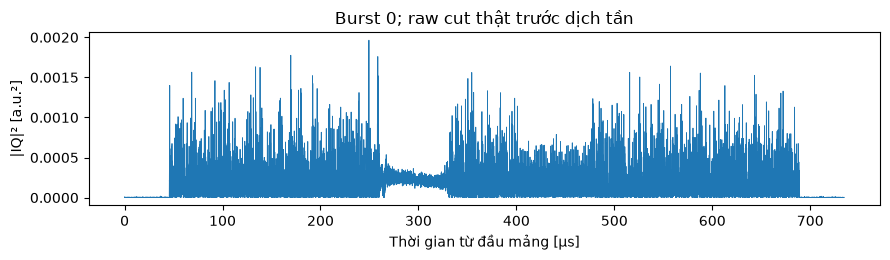

Nhận xét: 10 ứng viên trong chunk; theo burst 0, 36725 mẫu.


In [3]:
candidates = (view.stage("detector", dsp.detect, chunk_iq, cfg.fs, chunk_start, CHUNK_INDEX)
              if chunk_iq is not None else None) or []
chosen, raw_cut = None, None
view.table([{"burst 0-based":i, "start mẫu":c.start, "end excl mẫu":c.end,
             "N":len(c.iq), "µs có padding":round(len(c.iq)/c.fs*1e6, 2)}
            for i, c in enumerate(candidates)])
if not candidates:
    print("Không tìm thấy burst trong chunk: kiểm Fs/format, CHUNK_INDEX và detector. Các khối sau sẽ bỏ qua.")
elif not 0 <= BURST_INDEX < len(candidates):
    print(f"BURST_INDEX phải trong 0..{len(candidates)-1}; không tự đổi sang burst khác.")
else:
    chosen = candidates[BURST_INDEX]
    raw_cut = chosen.iq
    assert np.array_equal(raw_cut, chunk_iq[chosen.start-chunk_start:chosen.end-chunk_start])
    view.describe("raw_cut", raw_cut, fs=chosen.fs, unit="a.u.", preview=3)
    view.power_plot(raw_cut, chosen.fs, f"Burst {BURST_INDEX}; raw cut thật trước dịch tần")
    print(f"Nhận xét: {len(candidates)} ứng viên trong chunk; theo burst {BURST_INDEX}, {len(raw_cut)} mẫu.")

## 3. Dịch tâm tần số và đổi Fs — một hàm gộp hai bước
**Vấn đề:** Đưa dải DroneID về quanh 0 Hz, rồi đưa lưới mẫu về Fs của phần OFDM.

**Từ mới:** CFO là lệch tần; ở đây còn gồm vị trí kênh trong băng thu. Resample tạo mẫu tại lưới thời gian mới.

**Vào → ra:** raw_cut → shifted (cùng Fs đầu vào) → resampled (15,36 MS/s trong baseline).

**Ý tưởng:** `y[n]=x[n]exp(−j2π f0 t[n])`: f0 là tâm Welch, t là thời gian, j²=−1. Code dùng linspace gồm điểm cuối; resample bằng np.interp tuyến tính.

**Python đang chạy:** `pipeline.prepare → helpers.estimate_offset/fshift/resample`; trả cả hai mảng để quan sát.

**Đối chiếu proto17:** `extract_bursts_from_file.m` dịch theo file_freq_offset; `get_fft_size.m`/`create_zc.m` ràng buộc Fs/NFFT. **Khác nhau:** Python tự ước lượng tâm, nội suy tuyến tính không lọc polyphase chống alias. Proto17 không nhận 50 MS/s trực tiếp: NFFT=Fs/15kHz phải là lũy thừa 2; 50→15,36 có tỷ lệ 192/625. Không đổi thuật toán baseline lượt này.

**Quan sát:** Fs, số mẫu, thời lượng và phổ trước/sau. Hình chuẩn hoá đỉnh riêng nên không so gain tuyệt đối.

**Tự kiểm tra Q3:** Vì sao không chỉ sửa Fs từ 50e6 thành 15.36e6 trên cùng mảng? Đáp án ở cuối notebook.

Tâm dải [Hz]: 9619140.625 ; dịch [Hz]: -9619140.625
shifted: shape=(36725,), dtype=complex128; đơn vị=a.u.
  Fs=5e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
resampled: shape=(11282,), dtype=complex128; đơn vị=a.u.
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian


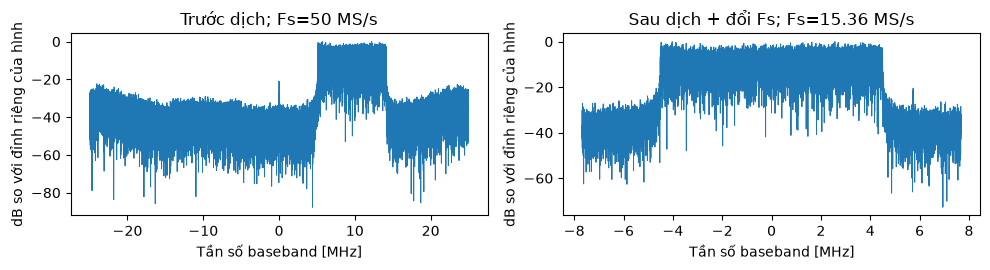

Nhận xét: 36725 → 11282 mẫu; chênh thời lượng 0.0052 µs.


In [4]:
prepared = view.stage("dịch tần/resample", dsp.prepare, chosen) if chosen is not None else None
if prepared is None:
    view.missing("dịch tần/resample")
else:
    print("Tâm dải [Hz]:", prepared["coarse_estimate_Hz"], "; dịch [Hz]:", prepared["applied_shift_Hz"])
    view.describe("shifted", prepared["shifted"], fs=cfg.fs, unit="a.u.")
    view.describe("resampled", prepared["resampled"], fs=prepared["fs"], unit="a.u.")
    view.spectra([("Trước dịch", raw_cut, cfg.fs), ("Sau dịch + đổi Fs", prepared["resampled"], prepared["fs"])])
    dt = len(prepared["resampled"])/prepared["fs"] - len(raw_cut)/cfg.fs
    print(f"Nhận xét: {len(raw_cut)} → {len(prepared['resampled'])} mẫu; chênh thời lượng {dt*1e6:.4f} µs.")
    if cfg.fs != prepared["fs"] and cfg.fs <= 15.46e6:
        print("LƯU Ý: baseline bỏ resample gần 15,36 MS/s nhưng gán Fs=15,36; đây là giới hạn code.")

## 4. Đồng bộ CP trước, ZC sau; bù CFO còn dư
**Vấn đề:** Tìm vị trí bắt đầu symbol và giảm lệch pha/tần trước FFT cuối.

**Từ mới:** CP là đoạn cuối symbol chép lên đầu. ZC là chuỗi tham chiếu có pha biết trước. Offset phân số mẫu là lệch nhỏ hơn khoảng cách mẫu.

**Vào → ra:** resampled → Packet: raw_samples_orig đã chuẩn hoá, start, detected_ffo [Hz], sampling_offset [mẫu].

**Ý tưởng:** `R=Σ x[n+N]conj(x[n])`, N=1024; CFO=`Fs·arg(R)/(2πN)`. CP cho start/CFO; FFT tạm dùng quét offset −15..15 để giảm RMS pha so ZC.

**Python đang chạy:** `pipeline.synchronize → Packet.__init__/find_fine_start/find_zc_offset/raw_data_to_symbols`; gộp chuẩn hoá, CP, nhiều FFT thử, ZC, kênh/pha phụ.

**Đối chiếu proto17:** `find_sto_cp.m`, `create_zc.m`, các khối CFO trong process_file.m. **Khác nhau:** Python đặt enable_zc_detection=False: root 600/147 là giả định, không vừa dò ra. Proto17 tìm burst bằng ZC trước CP, thêm CFO theo bin.

**Quan sát:** start trên lưới 15,36 MS/s, CFO còn dư, offset phân số. Constructor có nhánh bù góc; get_symbol_data FFT lại không truyền angle đó.

**Tự kiểm tra Q4:** In root 600/147 có chứng minh vừa nhận dạng ZC không? Đáp án ở cuối notebook.

In [5]:
packet = view.stage("đồng bộ CP/ZC", dsp.synchronize, prepared) if prepared is not None else None
if packet is None:
    view.missing("đồng bộ CP/ZC")
else:
    view.describe("packet.raw_samples_orig (normalize)", packet.raw_samples_orig, fs=packet.Fs, unit="a.u.")
    print("start [mẫu resampled]:", packet.start, "; start [µs]:", packet.start/packet.Fs*1e6)
    print("CFO còn dư [Hz]:", packet.detected_ffo, "; bù [Hz]:", -packet.detected_ffo)
    print("Offset phân số [mẫu]:", packet.sampling_offset, "; roots giả định: 600/147")
    print(f"Nhận xét: đỉnh sau normalize = {np.max(np.abs(packet.raw_samples_orig)):.6f}; chưa chứng minh CRC.")

packet.raw_samples_orig (normalize): shape=(11282,), dtype=complex128; đơn vị=a.u.
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
start [mẫu resampled]: 702 ; start [µs]: 45.703125
CFO còn dư [Hz]: -5791.512765718189 ; bù [Hz]: 5791.512765718189
Offset phân số [mẫu]: -4.1891891891891895 ; roots giả định: 600/147
Nhận xét: đỉnh sau normalize = 1.000000; chưa chứng minh CRC.


## 5. Bỏ CP, FFT và chọn carrier — kiểm đúng đường vào QPSK
**Vấn đề:** Tách sóng mang OFDM từ mỗi cửa sổ thời gian đúng vị trí.

**Từ mới:** OFDM ghép nhiều sóng mang trực giao; FFT đổi mẫu thời gian thành hệ số phức từng sóng mang; DC là bin 0 Hz.

**Vào → ra:** Packet đã căn → 9 symbol còn CP, full_fft (9×601), raw_fft (7×601) bỏ hai ZC nhưng còn DC.

**Ý tưởng:** `X[k]=Σ x[n]exp(−j2πkn/N)`: n chỉ mẫu, k chỉ carrier, N=1024; Δf=Fs/N=15 kHz. Bỏ CP [80,72,…,80], lấy bin −300..300.

**Python đang chạy:** `pipeline.symbols → Packet.get_symbol_data/raw_data_to_symbols → helpers.tfft`. time_with_cp/full_fft là đầu ra thực của FFT pass dùng tính kênh; so chính xác với pass QPSK.

**Đối chiếu proto17:** `extract_ofdm_symbol_samples.m`, `get_data_carrier_indices.m`, `get_cyclic_prefix_lengths.m`. **Khác nhau:** Python trả 601 bin cả DC và bỏ ZC indices [3,5] trước QPSK; proto17 FFT đầy đủ rồi chọn 600 carrier bỏ DC. CP và NFFT trùng ở Fs=15,36 MS/s.

**Quan sát:** Mảng symbol còn CP có độ dài khác nhau; sau bỏ CP phải còn 1024. Kiểm raw_fft bằng full_fft sau bỏ đúng ZC, không dùng FFT nhánh phase phụ của constructor.

**Tự kiểm tra Q5:** Vì sao còn 7×601 trước QPSK nhưng sau này chỉ lấy 6×600×2 bit? Đáp án ở cuối notebook.

time_with_cp[0]: shape=(1104,), dtype=complex128; đơn vị=a.u.
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
time_with_cp[0][cp:]: shape=(1024,), dtype=complex128; đơn vị=a.u.
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
full_fft: shape=(9, 601), dtype=complex128; đơn vị=FFT a.u.; Δf=Fs/NFFT
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
raw_fft (bỏ ZC): shape=(7, 601), dtype=complex128; đơn vị=FFT a.u.
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian


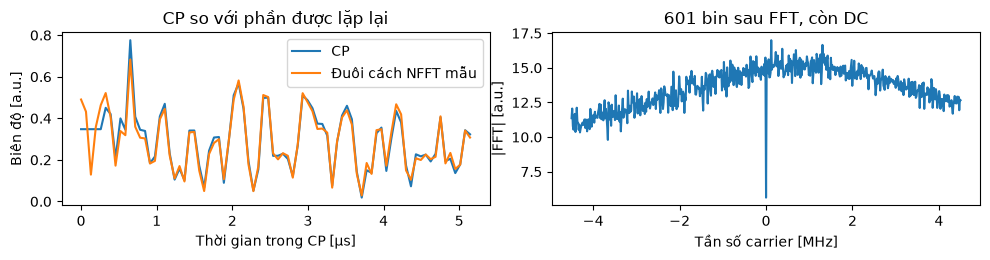

Nhận xét: CP=[80, 72, 72, 72, 72, 72, 72, 72, 80]; NFFT=1024; Δf=15000 Hz; hai FFT pass khớp chính xác.


In [6]:
ofdm = view.stage("OFDM/FFT", dsp.symbols, packet, cfg.mode) if packet is not None else None
if ofdm is None:
    view.missing("OFDM/FFT")
else:
    full_fft, time_with_cp = ofdm["full_fft"], ofdm["time_with_cp"]
    selected_symbols = [i for i in range(len(time_with_cp)) if i not in packet.ZC_SYMBOL_IDX]
    assert np.array_equal(full_fft[selected_symbols], ofdm["raw_fft"])
    cp = ofdm["cp_lengths"][0]
    view.describe("time_with_cp[0]", time_with_cp[0], fs=packet.Fs, unit="a.u.")
    view.describe("time_with_cp[0][cp:]", time_with_cp[0][cp:], fs=packet.Fs, unit="a.u.")
    view.describe("full_fft", full_fft, fs=packet.Fs, unit="FFT a.u.; Δf=Fs/NFFT")
    view.describe("raw_fft (bỏ ZC)", ofdm["raw_fft"], fs=packet.Fs, unit="FFT a.u.")
    view.cp_fft_plot(time_with_cp[0], cp, full_fft[0], packet.Fs)
    print(f"Nhận xét: CP={ofdm['cp_lengths']}; NFFT={ofdm['NFFT']}; Δf={packet.Fs/ofdm['NFFT']:g} Hz; hai FFT pass khớp chính xác.")

## 6. Cân bằng kênh: được tính nhưng không nằm trên baseline QPSK
**Vấn đề:** Kênh truyền có thể đổi biên độ/pha từng carrier; cần biết code có thực sự sửa nó không.

**Từ mới:** H[k] là đáp ứng kênh ở carrier k. Equalize nghĩa là bù ảnh hưởng H; chia cho H rất nhỏ có thể khuếch đại nhiễu.

**Vào → ra:** Hai ZC nhận → channel (601,), equalized (7×601); qpsk_input vẫn là raw_fft trong mode baseline.

**Ý tưởng:** `H=Yzc/Xzc`, Yzc là ZC nhận, Xzc là tham chiếu; lấy trung bình hai H rồi `Xhat=Y/H`. Xhat chỉ chẩn đoán trong baseline.

**Python đang chạy:** `pipeline.symbols`; vendor `Packet.estimate_channel/symbol_equalized`. Không đổi mode khi học baseline.

**Đối chiếu proto17:** `calculate_channel.m` và process_file.m: `channel=channel1; data_carriers=data_carriers.*channel`. **Khác nhau:** Proto17 thực áp dụng hệ số Xzc/Yzc của ZC đầu. Python baseline không dùng equalized; nhánh equalized là thử nghiệm riêng. Biến channel_phase_adj của proto17 được tính nhưng không áp dụng.

**Quan sát:** Kiểm bằng mảng thật qpsk_input == raw_fft. Hình equalized có nhãn chẩn đoán, không được gọi là đầu vào baseline.

**Tự kiểm tra Q6:** Chỉ nhìn thấy hình constellation equalized có đủ kết luận baseline dùng nó không? Đáp án ở cuối notebook.

channel: shape=(601,), dtype=complex128; đơn vị=H tương đối
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
equalized: shape=(7, 601), dtype=complex128; đơn vị=FFT a.u.
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian
qpsk_input: shape=(7, 601), dtype=complex128; đơn vị=FFT a.u.
  Fs=1.536e+07 mẫu phức/s; trục thời gian chỉ áp dụng cho mảng mẫu thời gian


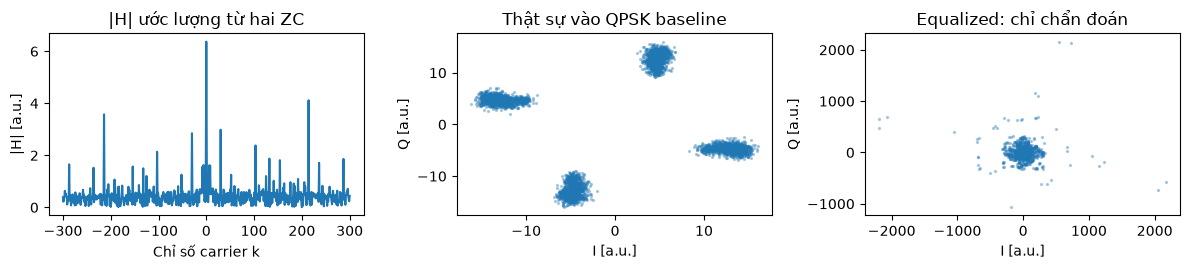

Nhận xét: qpsk_input bằng raw_fft: True ; bằng equalized: False


In [7]:
baseline_uses_raw = None
if ofdm is None:
    view.missing("cân bằng kênh")
else:
    for name in ("channel", "equalized", "qpsk_input"):
        view.describe(name, ofdm[name], fs=packet.Fs, unit="H tương đối" if name=="channel" else "FFT a.u.")
    baseline_uses_raw = np.array_equal(ofdm["qpsk_input"], ofdm["raw_fft"])
    assert baseline_uses_raw
    view.channel_plot(ofdm)
    print("Nhận xét: qpsk_input bằng raw_fft:", baseline_uses_raw,
          "; bằng equalized:", np.array_equal(ofdm["qpsk_input"], ofdm["equalized"]))

## 7. QPSK và lựa chọn hướng — quan sát vòng thử thật của app
**Vấn đề:** Đổi mỗi điểm phức thành nhãn hai bit; xử lý hướng quay chưa biết mà không chọn pha theo kết quả cũ.

**Từ mới:** QPSK dùng bốn góc pha/quadrant, mang 2 bit mỗi điểm. Hard decision chọn cứng quadrant, không giữ độ tin cậy mềm.

**Vào → ra:** qpsk_input (7×601) → labels (7×601, số 0..3) ở hướng mà mode đang chọn thực sự giữ.

**Ý tưởng:** App thử phase 0..3 qua QPSK→descramble→FEC→parse/CRC. Baseline dừng tại parse đầu kể cả CRC fail; turbo tiếp tục đến khi cả CRC24 và CRC16 pass hoặc hết 4 hướng.

**Python đang chạy:** `pipeline.decode_candidate/decide → qpsk.Decoder.raw_data_to_symbol_bits/get_symbol_bits`. phase_trace mới chỉ ghi lại mảng của các lần thử, không đổi quyết định.

**Đối chiếu proto17:** `quantize_qpsk.m`, process_file.m vòng symbol. **Khác nhau:** Proto17 ánh xạ dấu I/Q cố định; Python dùng masks [1,2]. Phases Python [0,1,2,3] tương ứng quay đầu vào proto17 [−90°,0°,90°,180°]. check_turbo.py so từng bit trên dữ liệu thật; trường hợp đúng trục có quy ước khác và được đếm riêng.

**Quan sát:** **Cell này gọi vòng gộp thật để biết đúng hướng, nên đã tính cả các bước phía sau.** Các cell 8–10 mở mảng đã ghi từ chính lần thử ấy, không tạo decoder thứ hai. FFT lần chạy lại phải khớp khối 5.

**Tự kiểm tra Q7:** Baseline có tiếp tục thử pha sau lần parse được nhưng CRC fail không? Đáp án ở cuối notebook.

labels: shape=(7, 601), dtype=int64; đơn vị=nhãn 0..3
  vài phần tử: [3 2 0 1 3 1 0 2]


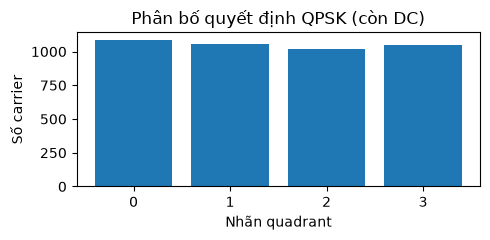

Nhận xét: đã thử [0]; đang mở phase 0; số nhãn [1088, 1054, 1020, 1045].
Các mảng dưới đây lấy từ phase_trace của vòng xử lý app/CLI; FFT đã so khớp khối trước.


In [8]:
phase_trace, frame_result, trial, labels = [], None, None, None
if chosen is not None and ofdm is not None:
    frame_result = view.stage("vòng thử thật", dsp.decode_candidate, chosen, cfg, phase_trace=phase_trace)
    if frame_result is not None and phase_trace:
        actual = frame_result["intermediates"]["symbols"]["qpsk_input"]
        assert np.array_equal(actual, ofdm["qpsk_input"])
        selected = frame_result.get("selected_phase", phase_trace[-1]["phase"])
        trial = next(t for t in phase_trace if t["phase"] == selected)
        labels = trial["labels"]
        view.describe("labels", labels, unit="nhãn 0..3", preview=8)
        counts = view.labels_plot(labels)
        print(f"Nhận xét: đã thử {[t['phase'] for t in phase_trace]}; đang mở phase {trial['phase']}; số nhãn {counts.tolist()}.")
        print("Các mảng dưới đây lấy từ phase_trace của vòng xử lý app/CLI; FFT đã so khớp khối trước.")
    else:
        view.missing("QPSK — chưa tới được vòng thử")
else:
    view.missing("QPSK")

## 8. Descramble: bỏ DC/first symbol và XOR Gold
**Vấn đề:** Bỏ cấu trúc không chứa payload rồi đảo phép xáo bit đã biết.

**Từ mới:** Scrambling là XOR với chuỗi giả ngẫu nhiên để phân bố bit, không phải mã hoá bí mật. Gold tạo bằng hai thanh ghi dịch LFSR.

**Vào → ra:** labels → bits_with_first_symbol (7×1200) → coded_bits (7200,) → descrambled (7200,).

**Ý tưởng:** Bỏ cột DC index300, tách hai bit bằng masks [1,2], bỏ symbol đầu. `d[i]=b[i] XOR c[i]`: b là coded bit, c là Gold(seed0x12345678, bỏ 1600 bit), d là bit sau descramble.

**Python đang chạy:** `pipeline.descramble → vendor.goldgen.gold`; mảng lấy từ trial[bits] của lần thử thật phía trên.

**Đối chiếu proto17:** `generate_scrambler_seq.m`; process_file.m giữ symbols [2,3,5,7,8,9] (1-based), reshape và bitxor. **Khác nhau:** Cùng ý tưởng Gold và 7200 bit, khác cách chọn carrier/nhãn trước XOR. Không suy ra hai implementation cho cùng bit chỉ vì cùng chiều dài.

**Quan sát:** Kiểm shape/dtype và số bit đổi sau XOR; không in toàn bitstream vì có thể khôi phục payload nhạy cảm.

**Tự kiểm tra Q8:** XOR Gold có sửa lỗi bit do nhiễu không? Đáp án ở cuối notebook.

In [9]:
bits = trial["bits"] if trial is not None else None
if bits is None:
    view.missing("descramble")
else:
    for name, array in bits.items():
        view.describe(name, array, unit="bit 0/1")
    changed = np.count_nonzero(bits["coded_bits"] != bits["descrambled"])
    print(f"Nhận xét: XOR đổi {changed}/{len(bits['coded_bits'])} bit; còn {len(bits['descrambled'])} bit cho FEC. Đây không phải số lỗi bit.")

bits_with_first_symbol: shape=(7, 1200), dtype=bool; đơn vị=bit 0/1
coded_bits: shape=(7200,), dtype=bool; đơn vị=bit 0/1
descrambled: shape=(7200,), dtype=bool; đơn vị=bit 0/1
Nhận xét: XOR đổi 3614/7200 bit; còn 7200 bit cho FEC. Đây không phải số lỗi bit.


## 9. FEC: baseline systematic-only hoặc TurboFEC thật
**Vấn đề:** Khôi phục bit thông tin; Turbo dùng thông tin dư để sửa lỗi trước khi kiểm CRC.

**Từ mới:** Systematic chứa bit thông tin trực tiếp; parity là bit dư giúp sửa lỗi. Rate matching hoán vị/chọn/lặp bit; rate unmatching đảo cách sắp xếp đó.

**Vào → ra:** Baseline: 7200→systematic 1412→177 byte. Turbo: 7200 byte 0/1→3×1412 int8 metric→1408 bit→176 byte, trong đó 3 byte CRC24 cuối.

**Ý tưởng:** Rate recovery đặt/lặp bit về ba luồng d0 systematic, d1/d2 parity. TurboFEC trao đổi độ tin cậy qua hai bộ giải mã thành phần, 4 vòng. LUT 0→−63, 1→+63 là hard metric cố định, chưa lấy độ tin cậy từ khoảng cách constellation.

**Python đang chạy:** `pipeline.decode_fec → turbo.turbo_decode → turbo_worker.cjs → turbo_bridge.cc → lte_rate_match_rv(rv=0) → lte_turbo_decode(K=1408,iterations=4)`; xem trial[fec]. Baseline vẫn gọi systematic_decode.

**Đối chiếu proto17:** `cpp/remove_turbo.cc`: rate recovery E=7200,D=1412, ba stream d1/d2/d3 → turbo 4 vòng → 1408 bit/176 byte → CRC24 LTE-A. **Khác nhau:** Bridge giữ LUT, E/D/K, rv, iterations và CRC như C++ gốc, chỉ thêm ABI/buffer chẩn đoán. Kiểm CLI gốc riêng cho đầu ra bằng nhau. MATLAB quantize/Gold được dịch trực tiếp để so giao diện; chưa chạy MATLAB.

**Quan sát:** Xem shape/dtype ba stream trước turbo_unterm sửa tail; không in bit/byte payload. Check_turbo.py còn đổi bit có seed và đặt parity=0 làm đối chứng; đây là dữ liệu dẫn xuất, không đo RF.

**Tự kiểm tra Q9:** CRC16 pass có chứng minh turbo đã sửa lỗi không? Đáp án ở cuối notebook.

In [10]:
fec = trial["fec"] if trial is not None else None
if fec is None:
    view.missing("systematic/rate unmatching")
else:
    for name in (("rate_unmatched",) if cfg.mode == "turbo" else ("cyclic", "systematic", "unmatched")):
        view.describe(name, fec[name], unit="metric int8, độ tin cậy không thứ nguyên" if name == "rate_unmatched" else "bit 0/1")
    view.describe("payload_bytes (không in nội dung)", np.frombuffer(fec["bytes"], dtype=np.uint8), unit="byte")
    print("parity_used =", fec["parity_used"], "; crc24_checked =", fec["crc24_checked"])
    if cfg.mode == "turbo":
        assert fec["rate_unmatched"].shape == (3, 1412) and len(fec["bytes"]) == 176
        print("Backend:", fec["backend"], "; số vòng:", fec["iterations"])
        print("CRC24 nhận:", fec["crc24_received"], "; tính trên 173 byte:", fec["crc24_calculated"],
              "; phần dư trên 176 byte:", fec["crc24_residue"], "; pass:", fec["crc24"])
    else:
        print("Baseline: 1412 bit → 177 byte, 4 bit đóng byte; không dùng parity, chưa kiểm CRC24.")

rate_unmatched: shape=(3, 1412), dtype=int8; đơn vị=metric int8, độ tin cậy không thứ nguyên
payload_bytes (không in nội dung): shape=(176,), dtype=uint8; đơn vị=byte
parity_used = True ; crc24_checked = True
Backend: proto17/TurboFEC C++ WASM SIMD / Node ; số vòng: 4
CRC24 nhận: c5f36d ; tính trên 173 byte: c5f36d ; phần dư trên 176 byte: 000000 ; pass: True


## 10. Parse và CRC16 được gọi cùng nhau
**Vấn đề:** Phân biệt đọc được struct với payload qua kiểm phát hiện lỗi.

**Từ mới:** Parse tách trường từ byte. CRC là checksum phát hiện lỗi, không xác thực nguồn phát; pass không chứng minh toạ độ đúng thực địa.

**Vào → ra:** 176 byte (turbo) hoặc 177 byte (baseline) → parse struct 91 byte đầu → CRC16 tính 89 byte đầu, so hai byte cuối struct little-endian.

**Ý tưởng:** crcmod polynomial 0x11021, init 0x3692, rev=True. So hai số CRC16; Python phải parse được chuỗi trước khi trả CRC từ parse_payload.

**Python đang chạy:** `pipeline.parse_payload → DroneIDPacket.__init__/crc/check_crc`; kết quả/attempts do decode_candidate vừa chạy.

**Đối chiếu proto17:** `cpp/remove_turbo.cc` chỉ kiểm CRC24 LTE-A trên 176 byte; chưa kiểm CRC16 payload. **Khác nhau:** CRC24 LTE-A: poly0x864CFB, init0, rev=False, 173 byte + 3 CRC byte big-endian. CRC16 payload có phạm vi/đa thức khác. Turbo chỉ xác nhận khi cả hai pass; baseline CRC24=None.

**Quan sát:** Bảng mỗi hướng có parsed, crc16 hoặc parse_error. Nếu không parse được thì CRC là chưa kiểm, không tự gọi CRC fail.

**Tự kiểm tra Q10:** Một candidate có UnicodeDecodeError khi parse thì CRC16 được tính và trượt chưa? Đáp án ở cuối notebook.

In [11]:
payload, crc16 = None, None
if frame_result is None:
    view.missing("parse/CRC16")
else:
    view.table(frame_result["attempts"])
    payload, crc16 = frame_result["payload"], frame_result["crc16"]
    if payload is not None:
        print("CRC16 nhận:", payload["crc-packet"], "; tính:", payload["crc-calculated"], "; pass:", crc16)
    print("Nhận xét: mode =", cfg.mode, "; status =", frame_result["status"], "; CRC24 =", frame_result["crc24"],
          "; đạt đủ kiểm tra:", dsp.confirmed(frame_result))
    if payload is None:
        print("Không parse được payload; không điền giá trị giả. Stage:", frame_result["error_stage"])
    elif not dsp.confirmed(frame_result):
        print("Payload đọc được nhưng chưa qua đủ CRC: chỉ chẩn đoán, chưa xác nhận.")

| phase | parsed | crc16 | crc24 | crc24_received | crc24_calculated | crc24_residue | backend |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | True | True | True | c5f36d | c5f36d | 000000 | proto17/TurboFEC C++ WASM SIMD / Node |

CRC16 nhận: f557 ; tính: f557 ; pass: True
Nhận xét: mode = turbo ; status = crc_pass ; CRC24 = True ; đạt đủ kiểm tra: True


## 11. Payload: trường nào đã biết và đơn vị nào chưa xác minh?
**Vấn đề:** Đọc kết quả có nguồn gốc, đồng thời che định danh/vị trí khi chia sẻ.

**Từ mới:** Little-endian là byte thấp trước. Raw là giá trị nguyên chưa gán đơn vị vật lý chắc chắn; app và home là hai nhóm trường khác nhau.

**Vào → ra:** payload dict → bảng tên/giá trị che/đơn vị từ FIELD_SCHEMA; không xuất raw bytes, serial hay toạ độ.

**Ý tưởng:** Parser dùng struct `<BBBHH16siihhhhhhQiiiiBB20sH`; lat/lon chia174533, altitude/height chia3.281. Đây là quy tắc kế thừa reverse engineering, chưa kiểm độc lập với ground truth.

**Python đang chạy:** `DroneIDPacket.__init__`, `pipeline.FIELD_SCHEMA/safe_payload`; GUI/CLI dùng cùng schema/redaction.

**Đối chiếu proto17:** Không có parser nhận tương ứng trong luồng process_file.m/remove_turbo.cc; C++ chỉ in hex. **Khác nhau:** Python đã có parser/CRC16; proto17 có turbo/CRC24 riêng. Velocity, d_1_angle, gps_time/flags và mốc độ cao chưa xác minh; không gọi d_1_angle là yaw hay gán m/s tuỳ ý.

**Quan sát:** Các trường nhạy cảm phải hiện [ẩn]. Kiểm CRC trước khi coi payload đáng tin; dữ liệu trong RAM vẫn riêng tư.

**Tự kiểm tra Q11:** Tại sao giữ v_north và d_1_angle dạng raw dù CRC pass? Đáp án ở cuối notebook.

In [12]:
if payload is None:
    view.missing("bảng payload")
else:
    safe = dsp.safe_payload(payload, redact=True)
    view.table([{"trường":k, "giá trị chia sẻ":v, "đơn vị / giới hạn":dsp.FIELD_SCHEMA.get(k, "chưa xác minh")}
                for k, v in safe.items()], limit=30)
    hidden = sum(v == "[ẩn]" for v in safe.values())
    print(f"Nhận xét: có {len(payload)} trường parse, {hidden} trường bị che; CRC16={crc16}. Không vẽ toạ độ trong notebook chia sẻ.")

| trường | giá trị chia sẻ | đơn vị / giới hạn |
| --- | --- | --- |
| pkt_len | 88 | byte; raw uint8, không dùng thay cho giới hạn 91 byte của parser |
| unk | 16 | raw uint8; ý nghĩa chưa xác minh |
| version | 2 | raw uint8; phiên bản payload theo parser |
| sequence_number | [ẩn] | raw uint16; số thứ tự |
| state_info | 7955 | raw uint16 flags; diễn giải trong code chưa kiểm nghiệm đầy đủ |
| serial_number | [ẩn] | text / nhận dạng; DroneIDPacket struct field 5 |
| longitude | [ẩn] | degree; raw/174533, reverse-engineered |
| latitude | [ẩn] | degree; raw/174533, reverse-engineered |
| altitude | 0.0 | m; code raw/3.281; mốc độ cao chưa xác minh độc lập |
| height | 0.0 | m; code raw/3.281; khác altitude |
| v_north | 0 | raw integer; đơn vị chưa xác minh độc lập |
| v_east | 0 | raw integer; đơn vị chưa xác minh độc lập |
| v_up | 0 | raw integer; đơn vị chưa xác minh độc lập |
| d_1_angle | 9575 | raw integer; không gán yaw, đơn vị/chuyển đổi chưa xác minh |
| gps_time | [ẩn] | raw uint64; không dùng làm thời gian tuyệt đối đã xác minh |
| app_lat | [ẩn] | degree; vị trí app, không tự đồng nhất với home |
| app_lon | [ẩn] | degree; vị trí app |
| longitude_home | [ẩn] | degree; home riêng biệt |
| latitude_home | [ẩn] | degree; home riêng biệt |
| device_type | Mini 2 | text từ bảng mã uint8 kế thừa, không chứng minh hỗ trợ mọi loại trong bảng |
| uuid_len | 0 | byte; raw uint8 |
| uuid | [ẩn] | text / định danh theo struct 20s |
| crc-packet | f557 | hex CRC16 nhận |
| crc-calculated | f557 | hex CRC16 tính |

Nhận xét: có 24 trường parse, 10 trường bị che; CRC16=True. Không vẽ toạ độ trong notebook chia sẻ.


## 12. Chạy toàn file và phân biệt lần chạy mới với báo cáo cũ
**Vấn đề:** Kiểm đường tích hợp app/CLI sau khi đã mở từng mảng của một burst.

**Từ mới:** Candidate, parse, CRC pass/fail và lỗi là các bộ đếm khác nhau; parse_failed không phải CRC fail.

**Vào → ra:** File thật + cfg → results từng candidate, summary và lỗi; chỉ bảng đã che được hiển thị.

**Ý tưởng:** decode_file đọc theo chunk, gọi detect rồi decode_candidate. Số đếm tính từ kết quả lần này; không assert phải bằng các số trong báo cáo cũ.

**Python đang chạy:** `pipeline.decode_file/summary`; chính CLI main và GUI worker gọi decode_file này.

**Đối chiếu proto17:** `process_file.m` lặp các burst và gọi remove_turbo; frames chỉ chứa stdout, chưa có schema thống kê như Python. **Khác nhau:** Summary luôn tách parse/CRC16; mode turbo có thêm CRC24/confirmed. File mẫu cắt/nối không là bài đo RF độc lập.

**Quan sát:** Dòng MỚI có thời gian chạy; CŨ đọc evidence đã tồn tại. Nếu khác, điều tra hash/config/phiên bản, không sửa dữ liệu để khớp.

**Tự kiểm tra Q12:** Lần mới khác báo cáo cũ thì nên sửa detector để có đúng 10 candidate ngay không? Đáp án ở cuối notebook.

In [13]:
runs, run_errors = {}, []
if RUN_FULL_FILE and reader is not None:
    paths = [input_path]
    known_dirs = [(LAB / "samples").resolve(),
                  (LAB.parent / "droneid_offline_audit_20261116/DroneSecurity/samples").resolve()]
    if RUN_SAMPLE_COMPARISON and input_path.parent in known_dirs and input_path.name in ("mini2_sm", "mavic_air_2"):
        paths = [input_path.parent / name for name in ("mini2_sm", "mavic_air_2")]
    for path in paths:
        rows = view.stage(f"toàn file {path.name}", dsp.decode_file, path, cfg, retain_limit=0)
        if rows is None:
            run_errors.append(path.name)
        else:
            runs[path.name] = rows
    print("MỚI — tính lại trong kernel này; bắt đầu UTC:", RUN_STARTED)
    view.table([dict(file=name, **dsp.summary(rows)) for name, rows in runs.items()])
    for name, rows in runs.items():
        problems = [{"file":name, "candidate":r["candidate"], "status":r["status"], "stage":r["error_stage"],
                     "lỗi parse":", ".join(sorted({a.get("parse_error", "") for a in r["attempts"]})).strip(", ")}
                    for r in rows if r["status"] in ("error", "parse_failed")]
        if problems:
            view.table(problems)
    old = []
    for name in runs:
        old_path = LAB / "evidence" / (name + ".json")
        if old_path.is_file() and name in ("mini2_sm", "mavic_air_2"):
            old.append(dict(file=name, **json.loads(old_path.read_text(encoding="utf-8"))["summary"]))
    if old:
        print("CŨ — evidence có trước lượt hoàn thiện notebook; chỉ đối chiếu, không kiểm bắt buộc:")
        view.table(old)
    print("Nhận xét: lần này xử lý được", len(runs), "file; lỗi/chưa chạy toàn file:", run_errors)
else:
    print("Không chạy toàn file: RUN_FULL_FILE=False hoặc reader chưa khả dụng.")

LEARNING_RUN = {"started_utc":RUN_STARTED, "python":sys.executable, "input":str(input_path),
    "chunk":CHUNK_INDEX, "burst":BURST_INDEX, "detected_in_chunk":len(candidates),
    "stages":{"read":chunk_iq is not None, "cut":chosen is not None, "prepare":prepared is not None,
              "sync":packet is not None, "fft":ofdm is not None, "qpsk":labels is not None,
              "descramble":bits is not None, "fec":fec is not None, "parsed":payload is not None},
    "qpsk_uses_raw":baseline_uses_raw, "selected_phase":trial["phase"] if trial else None,
    "decoder_mode":cfg.mode, "selected_crc16":crc16, "selected_crc24":frame_result.get("crc24") if frame_result else None,
    "crc24_checked":fec.get("crc24_checked",False) if fec else False, "parity_used":fec.get("parity_used",False) if fec else False,
    "summaries":{name:dsp.summary(rows) for name,rows in runs.items()}, "file_errors":run_errors}

MỚI — tính lại trong kernel này; bắt đầu UTC: 2026-11-18T16:08:25.509745+00:00


| file | candidates | parsed | crc_pass | crc_fail | errors | crc24_pass | crc24_fail | crc24_unselected | crc24_attempt_pass | crc24_attempt_fail | confirmed |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| mini2_sm | 10 | 10 | 10 | 0 | 0 | 10 | 0 | 0 | 10 | 15 | 10 |
| mavic_air_2 | 3 | 1 | 1 | 0 | 2 | 1 | 0 | 2 | 1 | 8 | 1 |

| file | candidate | status | stage | lỗi parse |
| --- | --- | --- | --- | --- |
| mavic_air_2 | 0 | parse_failed | payload | UnicodeDecodeError |
| mavic_air_2 | 1 | parse_failed | payload | UnicodeDecodeError |

CŨ — evidence có trước lượt hoàn thiện notebook; chỉ đối chiếu, không kiểm bắt buộc:


| file | candidates | parsed | crc_pass | crc_fail | errors |
| --- | --- | --- | --- | --- | --- |
| mini2_sm | 10 | 9 | 7 | 2 | 1 |
| mavic_air_2 | 3 | 1 | 1 | 0 | 2 |

Nhận xét: lần này xử lý được 2 file; lỗi/chưa chạy toàn file: []


## Đáp án tự kiểm tra — đọc sau khi tự trả lời
**Q1.** Một mẫu gồm I và Q; mỗi float32 4 byte, tổng 8 byte. Fs đếm cặp I/Q, không đếm từng số thực.

**Q2.** Không. Detector tạo giả thuyết; cần đồng bộ, demap, parse rồi CRC. Có false positive và burst kém chất lượng.

**Q3.** Đổi nhãn không đổi mẫu, làm sai thời gian CP/FFT và tần số. Cần resample; np.interp baseline vẫn có giới hạn aliasing.

**Q4.** Không. Code tắt tìm root và gán 600/147. ZC vẫn dùng tìm offset mẫu; cần công bố giả định cấu hình.

**Q5.** 9 symbol trừ hai ZC còn 7; 601 gồm DC. Sau quyết định bỏ DC và symbol đầu, còn 6×600×2=7200 bit.

**Q6.** Không. Phải đọc caller và kiểm mảng qpsk_input. Baseline chọn raw_fft, kể cả đã tính/vẽ equalized.

**Q7.** Baseline dừng ở parse đầu. Turbo chỉ dừng sớm khi cả CRC24 và CRC16 pass; nếu không có hướng đạt, giữ lần parse đầu để chẩn đoán, không xác nhận mục tiêu.

**Q8.** Không. Nó đảo phép scrambling, và XOR cùng chuỗi lần nữa sẽ trả bit cũ. Sửa lỗi cần FEC dùng thông tin dư thừa.

**Q9.** Không. Cần đường gọi có cả parity, đầu ra 176 byte/CRC24, đối chiếu C++ gốc và thử lỗi có kiểm soát. Baseline CRC16 pass vẫn có thể chứa lỗi bên ngoài 91 byte payload.

**Q10.** Không nhất thiết; parser đọc chuỗi trước khi hoàn thành CRC. Trong pipeline này trạng thái là parse_failed và CRC16=None, tách khỏi crc_fail.

**Q11.** CRC chỉ kiểm tính toàn vẹn theo checksum, không chứng minh hệ số đổi đơn vị/ý nghĩa trường. Cần tài liệu/đo đối chiếu độc lập; không đoán yaw hoặc m/s.

**Q12.** Không. Kiểm hash IQ, Fs/format, mode/chunk và phiên bản trước, ghi khác biệt thật. Đếm candidate không phải mục tiêu tối ưu ép khớp.

## Những phần chưa đạt toàn bộ đề

- **Turbo đã tích hợp riêng, giữ baseline để đối chiếu.** Chạy lại với DECODER_MODE="turbo", BURST_INDEX=6 trên mini2_sm để quan sát khung baseline fail. Native EXE/DLL bị Windows Application Control chặn; backend đang chạy là C/C++ WebAssembly SIMD qua Node. Chưa kiểm máy sạch, chưa có soft demapper theo khoảng cách điểm.
- Equalization chỉ là nhánh quan sát/thử nghiệm; cần chứng minh một nhánh áp dụng thật có kết quả đúng trước khi thay baseline.
- SNR: chưa có phép đo được hiệu chuẩn. CFO có ước lượng; các bài thử nhiễu/CFO trước đây chỉ là biến đổi trên capture, không phải RF thực địa. Chưa có thí nghiệm đa đường có ground truth.
- Payload: vận tốc, góc, gps_time/flags và mốc độ cao chưa xác minh độc lập. Không gọi CRC pass là xác thực danh tính hay vị trí thực địa.
- Detector/timing chỉ thử cấu trúc 9 symbol; file/model khác có thể không giải được. Không che lỗi bằng dữ liệu mô phỏng.

Điểm bắt đầu duy nhất: [START_HERE.md](../START_HERE.md). App/CLI dùng cùng pipeline; notebook này không tạo bộ giải mã độc lập.
Không cập nhật notebook trùng tên ở thư mục bên ngoài dự án, không xây GUI mới/đóng gói exe/chuyển môi trường.